In this exercise I will be using the diabetes data set from sklearn and perform linear regression on it to find the line of best fit to the data for predictions. I will need to use a polynomial function to best fit the curved data while also comparing the results from the normal model and curve using learning curves

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

In [23]:
from sklearn.datasets import load_diabetes
X,y = load_diabetes(return_X_y=True)

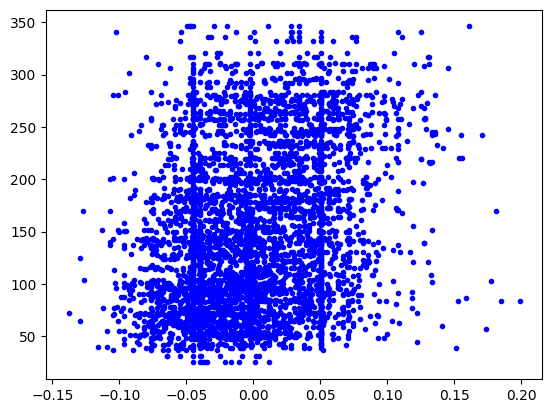

In [24]:
from matplotlib import pyplot as plt
plt.plot(X,y,'b.')
plt.show()

In [25]:
poly_pipeline = Pipeline([
    ('polynomial', PolynomialFeatures(degree=2)),
    ('model', LinearRegression())
]) #adds a degree to better fit the data


In [26]:
training_sizes, train_scores, val_scores = learning_curve(LinearRegression(), X, y, train_sizes=np.linspace(0.1,1.0,60), cv=5, scoring='neg_mean_squared_error')

In [27]:
train_means = -train_scores.mean(axis=1) #mean per size
val_means = -val_scores.mean(axis=1)


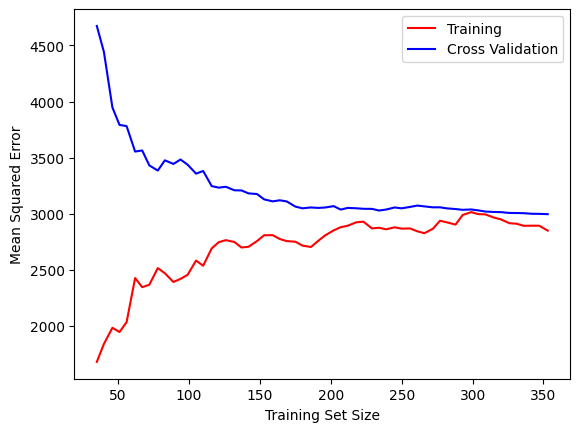

In [32]:
plt.plot(training_sizes,train_means, 'r-', label='Training')
plt.plot(training_sizes,val_means, 'b-', label='Cross Validation')
plt.xlabel('Training Set Size')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.show()

In [33]:
size, train_score, val_score = learning_curve(poly_pipeline, X, y, cv=5, scoring='neg_mean_squared_error', train_sizes=np.linspace(0.1,1.0,60))


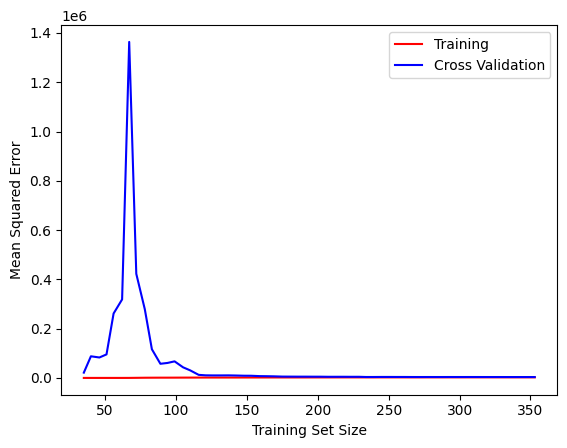

In [34]:
train_score = -train_score.mean(axis=1)
val_score = -val_score.mean(axis=1)

plt.plot(size,train_score, 'r-', label='Training')
plt.plot(size,val_score, 'b-', label='Cross Validation')
plt.xlabel('Training Set Size')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.show()